In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [3]:
df = pd.read_csv("Wholesale customers data.csv")

df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [5]:
df.isnull()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...
435,False,False,False,False,False,False,False,False
436,False,False,False,False,False,False,False,False
437,False,False,False,False,False,False,False,False
438,False,False,False,False,False,False,False,False


In [6]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [7]:
features = [
    'Fresh',
    'Milk',
    'Grocery',
    'Frozen',
    'Detergents_Paper',
    'Delicassen'
]

x = df[features]

x.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [8]:
scaler = StandardScaler()

x_scaled = scaler.fit_transform(x)

print("Scaled Data Shape:", x_scaled.shape)

Scaled Data Shape: (440, 6)


In [23]:
# MANUAL METHOD
kmeans_manual = KMeans(n_clusters=3, random_state=42, n_init=10)

labels_manual = kmeans_manual.fit_predict(x_scaled)

print("Manual K:", 3)

Manual K: 3


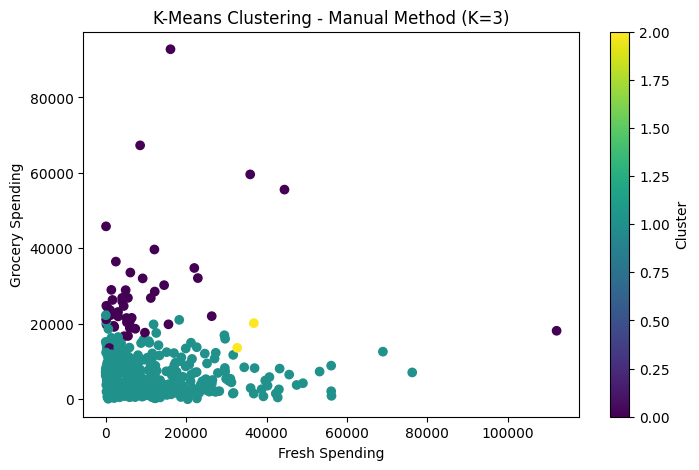

In [24]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x['Fresh'],
    x['Grocery'],
    c=labels_manual,
    cmap='viridis'
)

plt.title('K-Means Clustering - Manual Method (K=3)')
plt.xlabel('Fresh Spending')
plt.ylabel('Grocery Spending')
plt.colorbar(label='Cluster')
plt.show()

[2640.0, 1956.124277522268, 1608.4311488289443, 1317.8383605390707, 1058.7712532570085, 915.7412597498404, 825.400252021833, 737.386203336268, 661.4495846389702, 605.9151092090293]


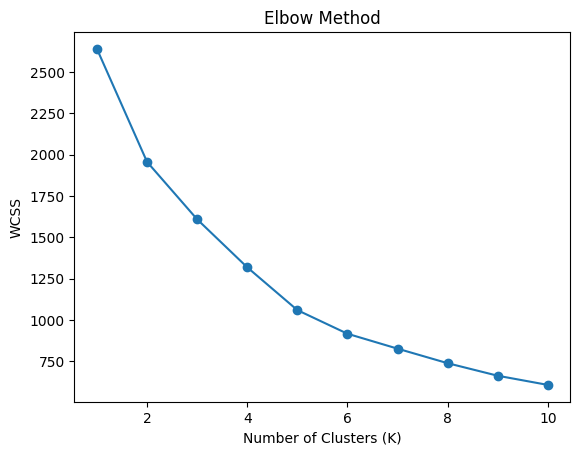

In [25]:
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(x_scaled)
    wcss.append(model.inertia_)
    
print(wcss)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

[0.5472146913441881, 0.5482872649700601, 0.34847138657014315, 0.3690403826812808, 0.3782288965882046, 0.3342819788182625, 0.3201161896109077, 0.30902833452574485, 0.3112143583568513]


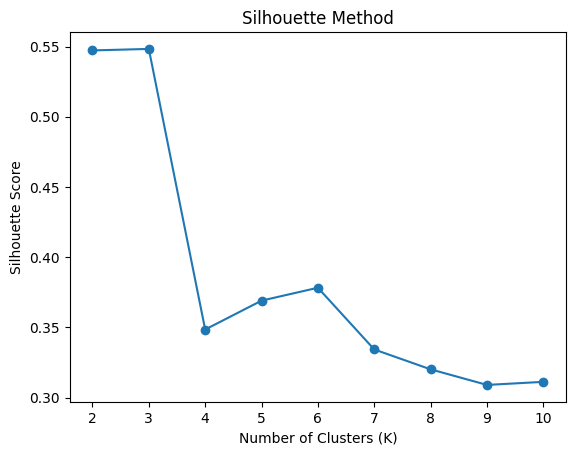

In [21]:
silhouette_scores = []

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(x_scaled)

    score = silhouette_score(x_scaled, labels)
    silhouette_scores.append(score)

print(silhouette_scores)

plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Method')
plt.show()

In [16]:
best_k = range(2, 11)[silhouette_scores.index(max(silhouette_scores))]

print("Best K using Silhouette Method:", best_k)
print("Highest Silhouette Score:", max(silhouette_scores))

Best K using Silhouette Method: 3
Highest Silhouette Score: 0.5482872649700601


In [26]:
manual_k = 3
elbow_k = 5  # Change this based on your Elbow graph
silhouette_k = best_k

comparison = pd.DataFrame({
    'Method': ['Manual Method', 'Elbow Method', 'Silhouette Method'],
    'Optimal K': [manual_k, elbow_k, silhouette_k]
})

print(comparison)

              Method  Optimal K
0      Manual Method          3
1       Elbow Method          5
2  Silhouette Method          3


In [27]:
print("Manual Method K:", manual_k)
print("Elbow Method K:", elbow_k)
print("Silhouette Method K:", silhouette_k)

if elbow_k == silhouette_k:
    print("Most suitable K:", elbow_k)
elif silhouette_k == manual_k:
    print("Most suitable K:", silhouette_k)
else:
    print("Compare the Elbow graph and Silhouette Scores to select the most suitable K.")

Manual Method K: 3
Elbow Method K: 5
Silhouette Method K: 3
Most suitable K: 3


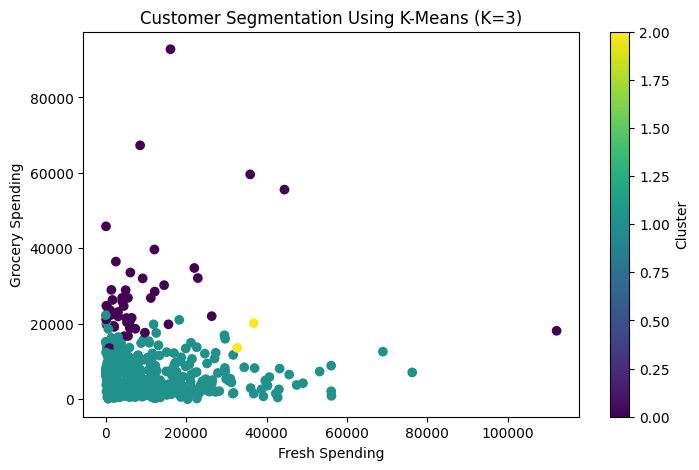

In [28]:
final_k = 3  # Replace with your selected K

final_model = KMeans(n_clusters=final_k, random_state=42, n_init=10)
final_labels = final_model.fit_predict(x_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    x['Fresh'],
    x['Grocery'],
    c=final_labels,
    cmap='viridis'
)

plt.xlabel('Fresh Spending')
plt.ylabel('Grocery Spending')
plt.title(f'Customer Segmentation Using K-Means (K={final_k})')
plt.colorbar(label='Cluster')
plt.show()